In [1]:
import numpy as np
import pandas as pd

In [8]:
np.random.seed(23)

mu_vec1 = np.array([0,0,0])
cov_mat1 = np.array([[1,0,0],[0,1,0],[0,0,1]])

class1_sample = np.random.multivariate_normal(mu_vec1, cov_mat1, 20)
df = pd.DataFrame(class1_sample , columns = ['feature1', 'feature2' ,'feature3'])
df['target'] =1 

mu_vec2 = np.array([1,1,1])
cov_mat2 = np.array([[1,0,0]
                     ,[0,1,0],
                     [0,0,1]])
class2_sample = np.random.multivariate_normal(mu_vec2, cov_mat2, 20)
df1 = pd.DataFrame(class2_sample, columns= ['feature1' , 'feature2', 'feature3'])



df1['target'] = 0
df = pd.concat([df, df1], ignore_index=True)
df = df.sample(40)


                  
                                            


In [9]:
df.head()

,feature1,feature2,feature3,target
2,-0.367548,-1.137460,-1.322148,1
34,0.177061,-0.598109,1.226512,0
14,0.420623,0.411620,-0.071324,1
11,1.968435,-0.547788,-0.679418,1
12,-2.506230,0.146960,0.606195,1


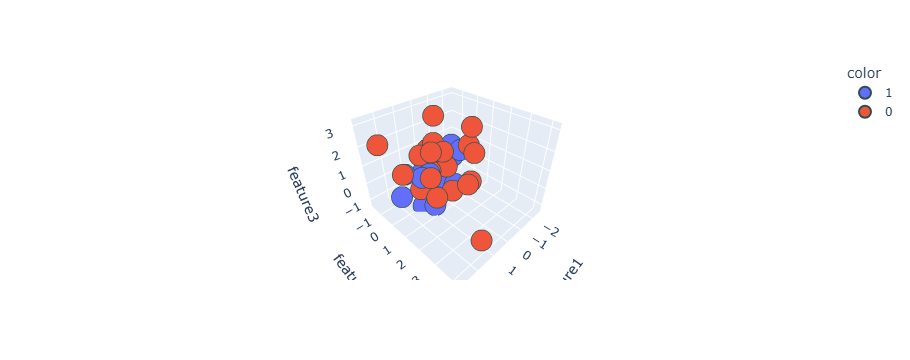

In [10]:
import plotly.express as px
#y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=df['feature1'], y=df['feature2'], z=df['feature3'],
              color=df['target'].astype('str'))
fig.update_traces(marker=dict(size=12,
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                  selector=dict(mode='markers'))

fig.show()
     

In [13]:
from sklearn.preprocessing import StandardScaler


In [14]:
scale = StandardScaler()

df.iloc[:,0:3] = scale.fit_transform(df.iloc[:,0:3]) 

In [16]:
covariance_matrix = np.cov([df.iloc[:,0],df.iloc[0:,1],df.iloc[:,2]])

In [17]:
print(covariance_matrix)

[[1.02564103 0.20478114 0.080118  ]
 [0.20478114 1.02564103 0.19838882]
 [0.080118   0.19838882 1.02564103]]


In [18]:
eigen_values , eigen_vectors= np.linalg.eig(covariance_matrix)

In [19]:
print(eigen_values)
print(eigen_vectors)

[1.3536065  0.94557084 0.77774573]
[[-0.53875915 -0.69363291  0.47813384]
 [-0.65608325 -0.01057596 -0.75461442]
 [-0.52848211  0.72025103  0.44938304]]


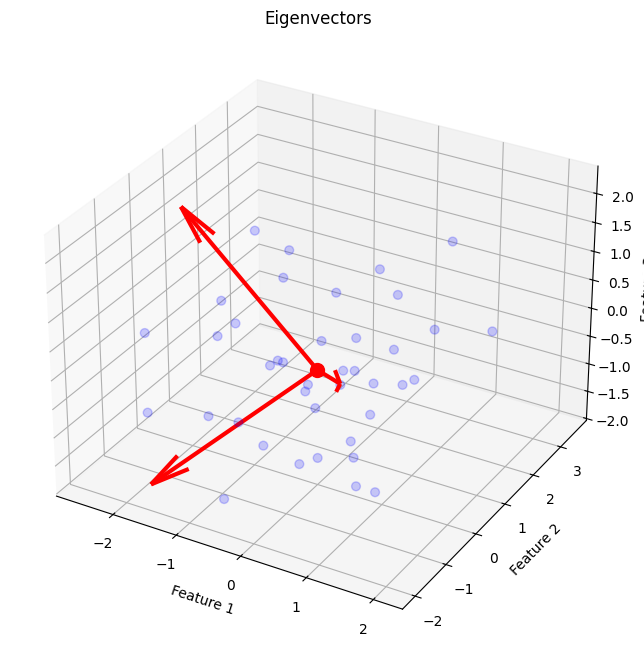

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Create 3D plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot data points
ax.scatter(
    df['feature1'],
    df['feature2'],
    df['feature3'],
    color='blue',
    alpha=0.2,
    s=40
)

# Calculate mean
mean = df[['feature1', 'feature2', 'feature3']].mean().values

# Plot mean
ax.scatter(
    *mean,
    color='red',
    s=100
)

# Plot eigenvectors
for v in eigen_vectors.T:
    ax.quiver(
        *mean,
        *(v * 3),
        color='red',
        linewidth=3,
        arrow_length_ratio=0.2
    )

# Labels
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')

ax.set_title('Eigenvectors')

plt.show()

In [25]:
pc = eigen_vectors[0:2]

In [26]:
pc

array([[-0.53875915, -0.69363291,  0.47813384],
       [-0.65608325, -0.01057596, -0.75461442]])

In [27]:
transformed_df = np.dot(df.iloc[:,0:3],pc.T)

In [33]:
new_df = pd.DataFrame(transformed_df, columns = ['PC1','PC2'])